In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
panel = pd.read_csv("../data/processed/panel.csv")

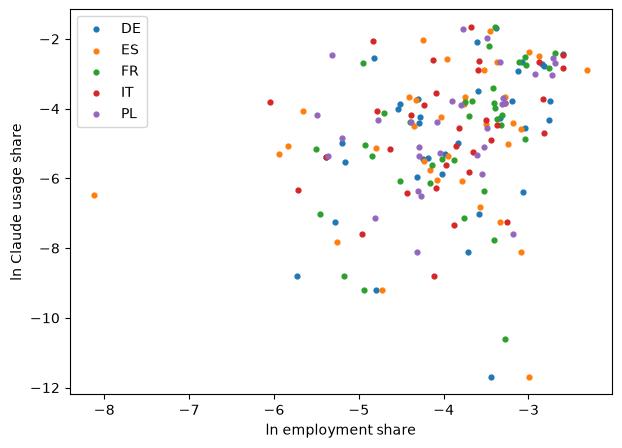

In [2]:
big = panel[panel["geo"].isin(["DE", "FR", "IT", "ES", "PL"])]
fig, ax = plt.subplots(figsize=(7, 5))
for country, sub in big.groupby("geo"):
    ax.scatter(sub["ln_e_2025"], sub["ln_s_may"], s=12, label=country)
ax.set_xlabel("ln employment share")
ax.set_ylabel("ln Claude usage share")
ax.legend()
plt.show()

In [3]:
d = panel[panel["main_sample"]].dropna(subset=["ln_s_may", "ln_e_2025"]).copy()
for col in ["ln_s_may", "ln_e_2025"]:
    r = d[col] - d[col].mean()
    for _ in range(100):
        r = r - r.groupby(d["geo"]).transform("mean")
        r = r - r.groupby(d["isco2"]).transform("mean")
    d["r_" + col] = r

x, y = d["r_ln_e_2025"], d["r_ln_s_may"]
beta = (x * y).sum() / (x ** 2).sum()
print("Cells:", len(d), " First estimate of beta:", round(beta, 3))

Cells: 482  First estimate of beta: 0.036


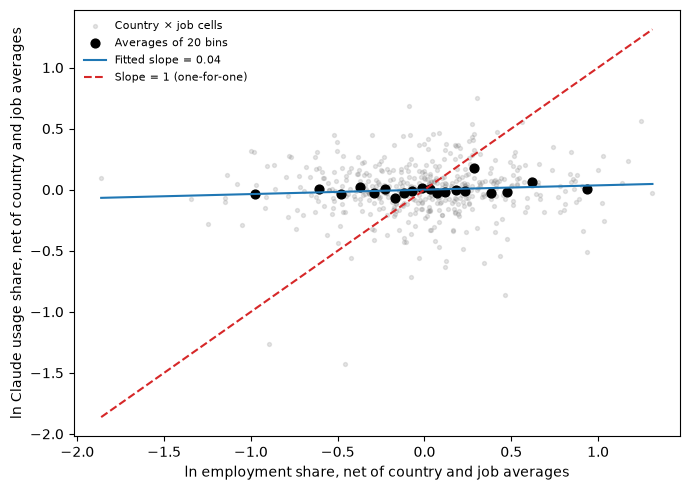

In [4]:
d["bin"] = pd.qcut(x, 20, labels=False)
bins = d.groupby("bin")[["r_ln_e_2025", "r_ln_s_may"]].mean()
xs = np.linspace(x.min(), x.max(), 100)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(x, y, s=8, alpha=0.2, color="grey", label="Country × job cells")
ax.scatter(bins["r_ln_e_2025"], bins["r_ln_s_may"], s=40, color="black", label="Averages of 20 bins")
ax.plot(xs, beta * xs, color="tab:blue", label=f"Fitted slope = {beta:.2f}")
ax.plot(xs, xs, color="tab:red", linestyle="--", label="Slope = 1 (one-for-one)")
ax.set_xlabel("ln employment share, net of country and job averages")
ax.set_ylabel("ln Claude usage share, net of country and job averages")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig("../output/figures/fig1_binscatter.pdf")
plt.show()